# Talent Data Lake — Explorer

**Audience:** anyone who wants to *see* what the pipeline does — the files it writes, what each layer looks like,
and how one record moves from source to answer. (The business answers themselves are in `insights.ipynb`.)

The lake is not a database: it is **folders of files in an S3 bucket**. pgAdmin can't show it, the S3 console can
only list the files — this notebook opens them and shows the rows.

| Layer | Folder | What it holds |
|---|---|---|
| **Bronze** | `bronze/` | Raw copies, never modified: a daily snapshot of every PostgreSQL table + the event files byte-for-byte |
| **Silver** | `silver/` | Cleaned, typed, validated data — one dataset per entity |
| **Quarantine** | `quarantine/` | Rows Silver rejected, with the reason and the original record |
| **Gold** | `gold/` | One table per business question |
| **Runs** | `_runs/` | A record (manifest) of every pipeline run |

**Sections:** 1 lake at a glance · 2 how data flows · 3 Bronze · 4 Silver · 5 Quarantine · 6 Gold ·
7 browse any dataset · 8 follow one employee · 9 pipeline runs.
Sections 7 and 8 have an **EDIT HERE** block — change it and re-run just that cell.

> **Running it.** Locally: start LocalStack, run the pipeline, open this notebook with the *Python (talent-pipeline)*
> kernel and **Run All**. On JupyterHub (cloud): upload this one file and **Run All**; cloud mode is detected
> automatically. To read the **AWS** lake from VS Code instead: run `./bin/setup-participant.sh` (fresh keys), set
> `FORCE_LOCAL = False` in the *EDIT HERE* block of the first code cell, and **Run All**.
> The notebook only *reads* the lake; it never changes anything.

## Setup — connect to the lake and list every file

In [1]:
import json
import os
import re
from collections import defaultdict

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display
from pyarrow.fs import FileSelector, FileType, S3FileSystem, resolve_s3_region  # pyright: ignore[reportPrivateImportUsage]

# ============================ EDIT HERE (only if needed) ============================
# Normally leave these empty: settings come from environment variables, and on JupyterHub the
# cloud mode is detected automatically. Fill them in only to override.
DATALAKE_BUCKET = ""   # e.g. "coding-workshop-datalake-77a23259"
AWS_REGION = ""        # e.g. "ap-south-1" (empty = ask S3 where the bucket is)
FORCE_LOCAL = None     # True = LocalStack, False = real AWS, None = detect
# ================== nothing to change below this line ==================

ON_JUPYTERHUB = "JUPYTERHUB_USER" in os.environ   # JupyterHub sets this; it only runs in the cloud
if FORCE_LOCAL is not None:
    IS_LOCAL = FORCE_LOCAL
elif os.environ.get("IS_LOCAL", "").strip():
    IS_LOCAL = os.environ["IS_LOCAL"].strip().lower() == "true"   # same variable as job.py
else:
    IS_LOCAL = not ON_JUPYTERHUB
participant = os.environ.get("PARTICIPANT_ID", "").strip()
BUCKET = (DATALAKE_BUCKET or os.environ.get("DATALAKE_BUCKET", "").strip()
          or (f"coding-workshop-datalake-{participant}" if participant else ""))
if not BUCKET:
    raise RuntimeError("Which data lake? Set DATALAKE_BUCKET in the EDIT HERE block above "
                       "(e.g. coding-workshop-datalake-<your participant id>), then run this cell again.")
REGION = AWS_REGION or os.environ.get("AWS_REGION") or os.environ.get("AWS_DEFAULT_REGION") or ""

if IS_LOCAL:  # LocalStack: dummy credentials, so real AWS keys are never used locally
    fs = S3FileSystem(access_key="test", secret_key="test", region=REGION or "us-east-1",
                      endpoint_override="localhost.localstack.cloud:4566", scheme="http")
else:         # AWS: credentials come from the environment / the node's IAM role
    if not REGION:
        try:
            REGION = resolve_s3_region(BUCKET)
        except OSError:
            raise RuntimeError(f"Bucket {BUCKET} not found in AWS - check DATALAKE_BUCKET above.") from None
    fs = S3FileSystem(region=REGION)
WHERE = "LocalStack" if IS_LOCAL else f"AWS ({REGION})"

LAYER_ORDER = ["source", "bronze", "silver", "quarantine", "gold", "_runs"]
LAYER_COLOURS = {"source": "#3B6EA5", "bronze": "#8C4A2F", "silver": "#6C7A89", "quarantine": "#B03A2E",
                 "gold": "#A87B00", "_runs": "#555555"}
COLUMN_NOTES = {   # what the columns the pipeline adds mean (everything else comes from the source)
    "_run_id": "lineage: the pipeline run that wrote this row",
    "_ingested_at": "lineage: when Bronze copied it (UTC)",
    "_source": "lineage: where it was copied from",
    "_bronze_run_id": "lineage: the run that wrote the Bronze snapshot it was cleaned from",
    "_source_file": "lineage: the raw Bronze file this row came from",
    "_source_line": "lineage: the line in that file (1 = first line)",
    "_as_of_date": "the date Gold figures are calculated for",
    "ingest_date": "partition folder: one Bronze snapshot per day",
    "run_date": "partition folder: the day of the run",
    "event_year": "partition folder", "event_month": "partition folder",
    "recorded_before_hire": "Silver flag: dated before the employee's hire date (kept, not dropped)",
    "reject_reason": "why the row was rejected (several reasons are joined with ';')",
    "raw_record": "the original record, exactly as received",
    "entity": "which Silver dataset the row was meant for",
}
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)


def list_files(prefix=""):
    """Every file under s3://BUCKET/<prefix> as {key: size in bytes} (folder markers are skipped)."""
    selector = FileSelector(f"{BUCKET}/{prefix}".rstrip("/"), recursive=True, allow_not_found=True)
    return {i.path[len(BUCKET) + 1:]: i.size for i in fs.get_file_info(selector) if i.type == FileType.File}


def dataset_of(key):
    """Which dataset a file belongs to: bronze/postgres/<table>, <layer>/<entity>, or _runs."""
    parts = key.split("/")
    if parts[:2] == ["bronze", "postgres"]:
        return "/".join(parts[:3])
    return "_runs" if parts[0] == "_runs" else "/".join(parts[:2])


def layer_of(name):
    return "source" if "://" in name else name.split("/")[0]


TABLE_CACHE = {}


def load(name):
    """A whole lake dataset (every Parquet file and partition) as a pyarrow Table, read once per session."""
    if name not in TABLE_CACHE:
        TABLE_CACHE[name] = pq.read_table(f"{BUCKET}/{name}", filesystem=fs)
    return TABLE_CACHE[name]


def schema_table(table):
    """Column, type and - for the columns the pipeline adds - what they mean."""
    return pd.DataFrame([{"column": f.name, "type": str(f.type), "note": COLUMN_NOTES.get(f.name, "")}
                         for f in table.schema])


def read_text(key):
    with fs.open_input_stream(f"{BUCKET}/{key}") as f:
        return f.read().decode("utf-8", errors="replace")


def read_json(key):
    return json.loads(read_text(key))


try:
    FILES = list_files()
    latest = read_json("_runs/latest.json")      # last COMPLETE successful pipeline run
    manifest = read_json(latest["manifest"])
except (OSError, KeyError) as exc:
    hint = ("Is LocalStack running and has the pipeline run? (./bin/start-dev.sh, seed_sources.sh, job.py)"
            if IS_LOCAL else
            "Check: (1) the pipeline has run in AWS; (2) the bucket name; (3) credentials - on JupyterHub the "
            "notebook server needs the node role (see data/README.md, Cloud Deployment); elsewhere (e.g. VS Code) run "
            "./bin/setup-participant.sh for fresh keys - they expire - then re-run this cell. 'credentials', "
            "'Expired', 'ACCESS_DENIED' or 'HTTP status 403' in the message below point to (3).")
    raise RuntimeError(f"Could not read the lake s3://{BUCKET} [{WHERE}]. {hint}\n"
                       f"Original error: {type(exc).__name__}: {str(exc)[:300]}") from None
metrics = {step["name"]: step["metrics"] for step in manifest["steps"]}
lineage = manifest["lineage"]                    # dataset -> the datasets it is built from

# Inventory: one row per dataset (row counts come from the Parquet footers - no data is read)
groups = defaultdict(dict)
for key, size in FILES.items():
    groups[dataset_of(key)][key] = size
inventory = pd.DataFrame([{
    "layer": layer_of(name), "dataset": name, "files": len(keys),
    "rows": (sum(pq.read_metadata(fs.open_input_file(f"{BUCKET}/{k}")).num_rows for k in keys if k.endswith(".parquet"))
             if any(k.endswith(".parquet") for k in keys) else None),
    "size_kb": round(sum(keys.values()) / 1024, 1),
} for name, keys in groups.items()])
inventory["rows"] = inventory["rows"].astype("Int64")
inventory = (inventory.assign(order=inventory["layer"].map(LAYER_ORDER.index))
             .sort_values(["order", "dataset"]).drop(columns="order").reset_index(drop=True))

display(Markdown(
    f"**Lake** `s3://{BUCKET}` [{WHERE}] · {len(FILES):,} files in {len(inventory)} datasets · "
    f"latest complete run `{latest['run_id']}` ({manifest['status']}, finished "
    f"{latest['finished_at'][:19].replace('T', ' ')} UTC)"))
inventory

**Lake** `s3://coding-workshop-datalake-77a23259` [LocalStack] · 845 files in 26 datasets · latest complete run `20261015T171915Z-6bf88104` (succeeded, finished 2026-10-15 17:19:22 UTC)

,layer,dataset,files,rows,size_kb
0,bronze,bronze/learning_activity,783,<NA>,7131.2
1,bronze,bronze/postgres/competencies,1,40,5.4
2,bronze,bronze/postgres/competency_assessments,1,4000,52.6
3,bronze,bronze/postgres/employees,1,2000,71.8
4,bronze,bronze/postgres/performance_reviews,1,4000,48.3
5,bronze,bronze/postgres/projects,1,33,6.4
6,bronze,bronze/postgres/talent_review,1,2000,17.8
7,bronze,bronze/postgres/teams,1,100,6.2
8,silver,silver/competencies,1,40,5.8
9,silver,silver/competency_assessments,1,4000,53.9


## 1. The lake at a glance

Each **dataset** is a folder; inside are **Parquet** files — a compressed, column-by-column file format that keeps
the column types (a date stays a date). Some datasets are split into **partition folders** such as
`ingest_date=2026-10-15/` or `event_year=2025/event_month=05/`, so a reader can skip folders it doesn't need.

Colours used in every chart: <span style="color:#3B6EA5">■ source</span>
<span style="color:#8C4A2F">■ Bronze</span> <span style="color:#6C7A89">■ Silver</span>
<span style="color:#B03A2E">■ quarantine</span> <span style="color:#A87B00">■ Gold</span>.

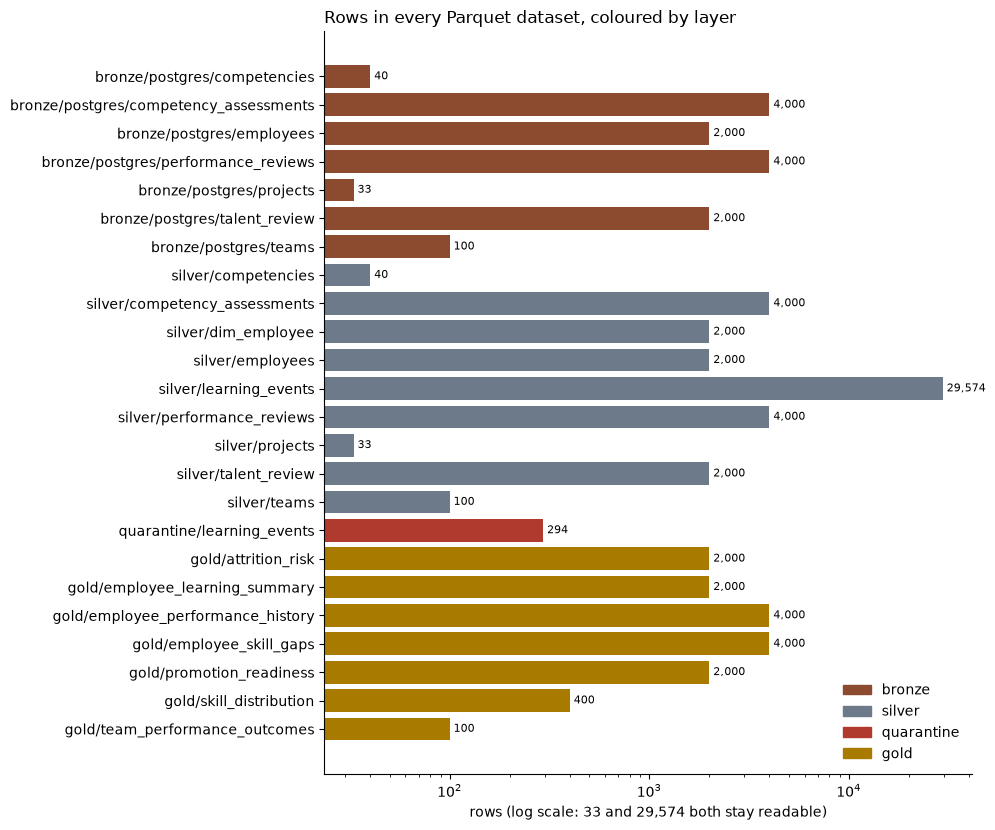

Not in the chart: `bronze/learning_activity` holds **783 raw event files** (7,131 KB). They are text (JSON Lines), not Parquet, so they have no row count until Silver parses them (section 4). `_runs` holds the run records (section 9).

In [2]:
shown = inventory.dropna(subset=["rows"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.3 * len(shown) + 1.2))
ax.barh(shown["dataset"], shown["rows"], color=shown["layer"].map(LAYER_COLOURS))
for y, rows in enumerate(shown["rows"]):
    ax.text(rows, y, f" {rows:,}", va="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("rows (log scale: 33 and 29,574 both stay readable)")
ax.set_title("Rows in every Parquet dataset, coloured by layer", loc="left")
ax.legend(handles=[Patch(color=LAYER_COLOURS[l], label=l) for l in LAYER_ORDER[1:5]
                   if l in set(shown["layer"])], loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

raw = inventory.set_index("dataset").loc["bronze/learning_activity"]
display(Markdown(
    f"Not in the chart: `bronze/learning_activity` holds **{raw['files']:,} raw event files** "
    f"({raw['size_kb']:,.0f} KB). They are text (JSON Lines), not Parquet, so they have no row count until Silver "
    f"parses them (section 4). `_runs` holds the run records (section 9)."))

## 2. How data flows through the layers

**Dataset lineage** — every arrow means "is built from". The diagram is drawn from the lineage recorded in the
latest run's manifest, which the pipeline generates from the same code it executes, so it can't drift from what
actually happens. Columns are ordered by how many steps a dataset is from its source.

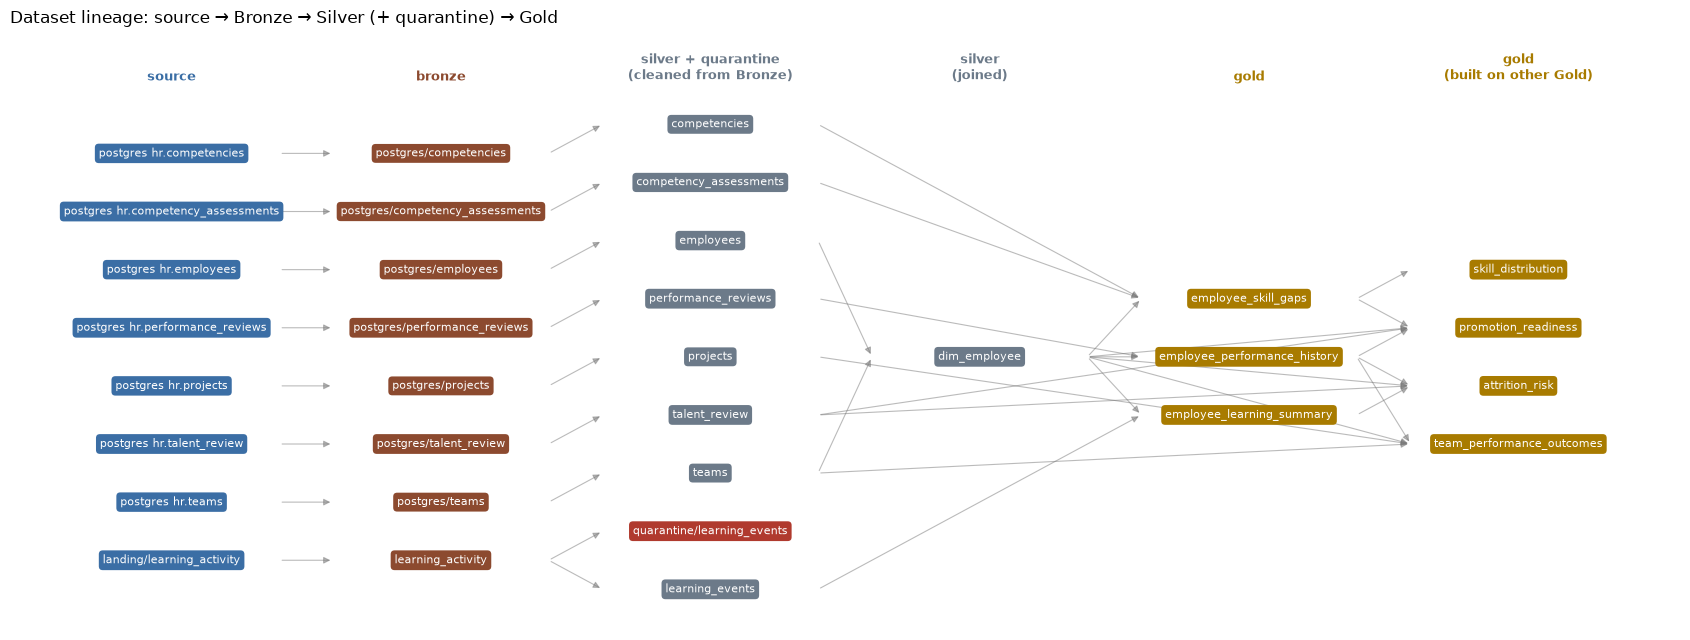

Not drawn, to keep the picture readable: 8 foreign-key *checks* between Silver tables (e.g. `silver/competency_assessments` is checked against `silver/employees`). Column-level lineage: `data/LINEAGE.md`.

In [3]:
existing = set(inventory["dataset"])


def is_check(src, dst):
    """Silver tables are cleaned from their own Bronze table and *checked* against other Silver tables
    (foreign keys, e.g. every review's employee_id must exist in silver/employees)."""
    return layer_of(src) == "silver" and any(layer_of(i) == "bronze" for i in lineage[dst])


# Quarantine datasets are only written when something is rejected: draw just the ones that exist.
edges = [(src, dst) for dst, srcs in lineage.items() for src in srcs
         if not (dst.startswith("quarantine/") and dst not in existing)]
build_edges = [(s, d) for s, d in edges if not is_check(s, d)]
nodes = sorted({n for edge in edges for n in edge})


def column_of(n):
    """source | Bronze | Silver (cleaned) | Silver (joined) | Gold | Gold (built on Gold)."""
    layer, inputs = layer_of(n), lineage.get(n, [])
    if layer == "source":
        return 0
    if layer == "bronze":
        return 1
    if layer in ("silver", "quarantine"):
        return 2 if any(layer_of(i) == "bronze" for i in inputs) else 3
    return 5 if any(layer_of(i) == "gold" for i in inputs) else 4


HEADERS = ["source", "bronze", "silver + quarantine\n(cleaned from Bronze)", "silver\n(joined)", "gold",
           "gold\n(built on other Gold)"]
columns, y = defaultdict(list), {}
for n in nodes:
    columns[column_of(n)].append(n)
for c in sorted(columns):   # place each node level with the average of its inputs (fewer crossing arrows)
    def level(n):
        inputs = [s for s, d in build_edges if d == n and s in y]
        return -sum(y[i] for i in inputs) / len(inputs) if inputs else 0
    col = sorted(columns[c], key=lambda n: (level(n), n))
    for i, n in enumerate(col):
        y[n] = (len(col) - 1) / 2 - i


def label(n):
    if n.startswith("postgres://"):
        return "postgres " + n.rsplit("/", 1)[-1]
    if "://" in n:
        return "landing/" + n.split("/", 3)[3].rstrip("/")
    return n if layer_of(n) == "quarantine" else n.split("/", 1)[1]


height = max(len(c) for c in columns.values())
fig, ax = plt.subplots(figsize=(17, 0.5 * height + 2))
for src, dst in build_edges:
    ax.annotate("", xy=(column_of(dst) - 0.4, y[dst]), xytext=(column_of(src) + 0.4, y[src]),
                arrowprops=dict(arrowstyle="-|>", color="#777777", alpha=0.5, lw=0.8))
for n in nodes:
    ax.text(column_of(n), y[n], label(n), ha="center", va="center", fontsize=8, color="white",
            bbox=dict(boxstyle="round,pad=0.35", fc=LAYER_COLOURS[layer_of(n)], ec="none"))
for c in columns:
    ax.text(c, height / 2 + 0.2, HEADERS[c], ha="center", va="bottom", fontsize=9.5, fontweight="bold",
            color=LAYER_COLOURS[next((layer_of(n) for n in columns[c] if layer_of(n) != "quarantine"),
                                     "quarantine")])
ax.set_xlim(-0.6, max(columns) + 0.6)
ax.set_ylim(-height / 2 - 0.2, height / 2 + 1.1)
ax.axis("off")
ax.set_title("Dataset lineage: source → Bronze → Silver (+ quarantine) → Gold", loc="left")
plt.tight_layout()
plt.show()
checks = sorted({(s, d) for s, d in edges if is_check(s, d)}, key=lambda e: (layer_of(e[1]) != "silver", e[1], e[0]))
display(Markdown(
    f"Not drawn, to keep the picture readable: {len(checks)} foreign-key *checks* between Silver tables "
    f"(e.g. `{checks[0][1]}` is checked against `{checks[0][0]}`). Column-level lineage: `data/LINEAGE.md`."
    if checks else ""))

**Row accounting** — the counts each step logged in the run manifest. Silver's rule is
**read = valid + quarantined**: every row it reads ends up in exactly one place, so nothing is silently dropped.
Rows *flagged* as recorded before hire are still valid — they are kept and marked, not removed.

In [4]:
bronze_m, silver_m, gold_m = metrics.get("bronze", {}), metrics.get("silver", {}), metrics.get("gold", {})
accounting = []
for table in [k[:-len("_rows")] for k in bronze_m if k.endswith("_rows")]:
    accounting.append({"dataset": table, "Bronze": f"{bronze_m[f'{table}_rows']:,} rows"})
accounting.append({"dataset": "learning_events",
                   "Bronze": f"{bronze_m.get('learning_files_listed', 0):,} files "
                             f"({bronze_m.get('learning_files_empty', 0)} empty)"})
for row in accounting:
    t = row["dataset"]
    read, valid, quarantined = (silver_m.get(f"{t}_{k}") for k in ("read", "valid", "quarantined"))
    row.update({"Silver read": read, "valid": valid, "quarantined": quarantined,
                "flagged before hire": silver_m.get(f"{t}_before_hire", 0),
                "read = valid + quarantined": "✓" if read == (valid or 0) + (quarantined or 0) else "✗"})
display(pd.DataFrame(accounting))
display(Markdown("**Gold:** " + " · ".join(f"`{k[:-len('_rows')]}` {v:,} rows"
                                           for k, v in gold_m.items() if k.endswith("_rows"))))

,dataset,Bronze,Silver read,valid,quarantined,flagged before hire,read = valid + quarantined
0,teams,100 rows,100,100,0,0,✓
1,competencies,40 rows,40,40,0,0,✓
2,employees,"2,000 rows",2000,2000,0,0,✓
3,projects,33 rows,33,33,0,0,✓
4,performance_reviews,"4,000 rows",4000,4000,0,666,✓
5,competency_assessments,"4,000 rows",4000,4000,0,234,✓
6,talent_review,"2,000 rows",2000,2000,0,0,✓
7,learning_events,783 files (1 empty),29868,29574,294,5161,✓


**Gold:** `employee_performance_history` 4,000 rows · `employee_skill_gaps` 4,000 rows · `promotion_readiness` 2,000 rows · `employee_learning_summary` 2,000 rows · `attrition_risk` 2,000 rows · `team_performance_outcomes` 100 rows · `skill_distribution` 400 rows

## 3. Bronze — raw copies, never modified

Bronze is the safety net: if a later step has a bug, Silver and Gold can be rebuilt from it without asking the
source systems again. Two kinds of data land here:

* **PostgreSQL tables** — a consistent snapshot of each table per day, in an `ingest_date=` partition folder.
  The columns are exactly the source table's, plus three lineage columns (`_run_id`, `_ingested_at`, `_source`).
* **Learning event files** — server-side copies of the landing bucket's JSON Lines files, byte-for-byte, broken lines
  included (Silver deals with them).

Change `BRONZE_TABLE` to look at another table.

In [5]:
BRONZE_TABLE = "employees"   # teams, competencies, employees, projects, performance_reviews, competency_assessments, talent_review

name = f"bronze/postgres/{BRONZE_TABLE}"
snapshot = load(name)
snapshots = sorted({k.split("/")[3] for k in groups[name]})
display(Markdown(f"`s3://{BUCKET}/{name}/` — **{snapshot.num_rows:,} rows**, "
                 f"{len(snapshots)} daily snapshot(s): {', '.join(snapshots)}"))
display(schema_table(snapshot))
snapshot.to_pandas().head(5)

`s3://coding-workshop-datalake-77a23259/bronze/postgres/employees/` — **2,000 rows**, 1 daily snapshot(s): ingest_date=2026-10-15

,column,type,note
0,employee_id,int64,
1,first_name,large_string,
2,last_name,large_string,
3,email,large_string,
4,team_id,int64,
5,job_level,large_string,
6,hire_date,date32[day],
7,_run_id,large_string,lineage: the pipeline run that wrote this row
8,_ingested_at,"timestamp[us, tz=UTC]",lineage: when Bronze copied it (UTC)
9,_source,large_string,lineage: where it was copied from


,employee_id,first_name,last_name,email,team_id,job_level,hire_date,_run_id,_ingested_at,_source,ingest_date
0,1,Heather,Davis,heather.davis.1@acme-corp.example,1,Director,2024-04-06,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,2026-10-15
1,2,Kristie,Heath,kristie.heath.2@acme-corp.example,1,Director,2021-05-23,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,2026-10-15
2,3,Brandon,Scott,brandon.scott.3@acme-corp.example,1,Senior Manager,2020-03-30,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,2026-10-15
3,4,Gregory,Williams,gregory.williams.4@acme-corp.example,1,IC3,2020-01-06,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,2026-10-15
4,5,Linda,Murray,linda.murray.5@acme-corp.example,1,IC1,2025-11-01,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,2026-10-15


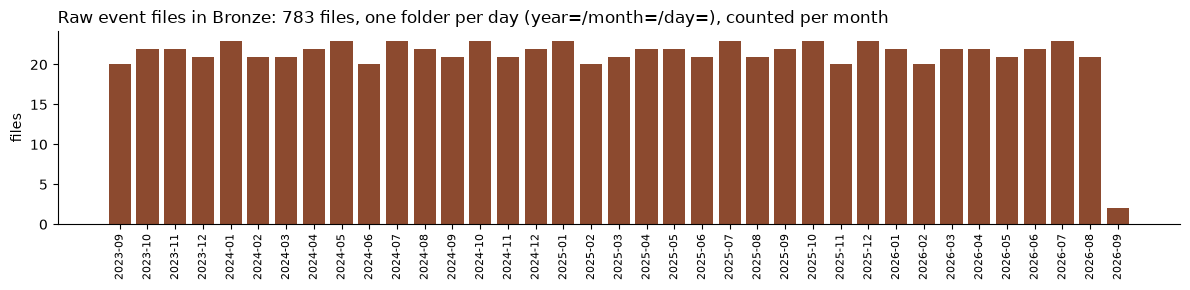

Empty files (kept as received, and reported by the pipeline): `bronze/learning_activity/year=2025/month=09/day=03/events-000.jsonl`

First 3 lines of bronze/learning_activity/year=2023/month=09/day=04/events-000.jsonl:

  {"event_id": "EV0000000001", "employee_id": "607", "event_date": "2023-09-04T17:09:00", "event_type": "course_completed", "course_name": "Pricing Strategy Fundamentals", "text": "Finished all modules of Pricing Strategy Fundamentals.", "score": null}
  {"event_id": "EV0000000002", "employee_id": "1357", "event_date": "2023-09-04T19:13:00", "event_type": "course_completed", "course_name": "Negotiation Tactics", "text": "Finished all modules of Negotiation Tactics.", "score": null}
  {"event_id": "EV0000000003", "employee_id": "495", "event_date": "2023-09-04T16:34:00", "event_type": "enrollment", "course_name": "Web Accessibility Standards", "text": "Enrolled in Web Accessibility Standards.", "score": null}

Compared with s3://coding-workshop-landing-77a23259/learning_activity/year=2023/month=09/day=04/events-000.jsonl: identical, byte for byte ✓


In [6]:
raw_files = groups["bronze/learning_activity"]
month = pd.Series({k: "-".join(re.search(r"year=(\d{4})/month=(\d{2})", k).groups()) for k in raw_files})
per_month = month.value_counts().sort_index()
empty = sorted(k for k, size in raw_files.items() if size == 0)

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(per_month.index, per_month.values, color=LAYER_COLOURS["bronze"])
ax.set_title(f"Raw event files in Bronze: {len(raw_files):,} files, one folder per day "
             "(year=/month=/day=), counted per month", loc="left")
ax.set_ylabel("files")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
display(Markdown("Empty files (kept as received, and reported by the pipeline): "
                 + (", ".join(f"`{k}`" for k in empty) if empty else "none")))

# Byte-for-byte: compare one Bronze file with the landing-bucket original it was copied from
sample = next(k for k in sorted(raw_files) if raw_files[k] > 0)
landing_bucket = manifest["config"]["landing_bucket"]
landing_key = sample.removeprefix("bronze/")
print(f"First 3 lines of {sample}:\n")
print("\n".join("  " + line for line in read_text(sample).splitlines()[:3]))
try:
    with fs.open_input_stream(f"{landing_bucket}/{landing_key}") as f:
        original = f.read()
    with fs.open_input_stream(f"{BUCKET}/{sample}") as f:
        copy = f.read()
    print(f"\nCompared with s3://{landing_bucket}/{landing_key}: "
          + ("identical, byte for byte ✓" if copy == original else "DIFFERENT ✗"))
except OSError as exc:
    print(f"\n(Couldn't read the landing bucket to compare: {str(exc)[:120]})")

## 4. Silver — cleaned, typed and validated

Silver applies a **schema contract** to every dataset: types, required fields, allowed values, ranges, unique keys
and links to other tables (an `employee_id` must exist in `employees`). Rows that pass go to Silver; rows that
fail go to quarantine (section 5). Silver also adds the `recorded_before_hire` flag and lineage columns.

**One event, Bronze → Silver.** Below is one raw line from a Bronze file and the Silver row made from it, found by
following the row's `_source_file` and `_source_line` back to Bronze.

In [7]:
events_table = load("silver/learning_events")
events = events_table.to_pandas()
row = events.sort_values(["_source_file", "_source_line"]).iloc[0]
raw_line = read_text(row["_source_file"]).splitlines()[row["_source_line"] - 1]
raw = json.loads(raw_line)
print(f"Bronze  {row['_source_file']}, line {row['_source_line']}:\n  {raw_line}\n")

types = {f.name: str(f.type) for f in events_table.schema}
derived = {"event_ts": "renamed from event_date (it is a timestamp)",
           "event_date": "derived: the date part of event_ts",
           "recorded_before_hire": "added: compared with the employee's hire date"}
trail = pd.DataFrame([{
    "Silver column": col,
    "Bronze (raw text)": json.dumps(raw["event_date" if col == "event_ts" else col]) if (
        col != "event_date" and (col in raw or col == "event_ts")) else "—",
    "Silver value": row[col], "Silver type": types[col],
    "what Silver did": derived.get(col, COLUMN_NOTES.get(col, "typed and validated")),
} for col in events.columns if col not in ("event_year", "event_month")])
trail

Bronze  bronze/learning_activity/year=2023/month=09/day=04/events-000.jsonl, line 1:
  {"event_id": "EV0000000001", "employee_id": "607", "event_date": "2023-09-04T17:09:00", "event_type": "course_completed", "course_name": "Pricing Strategy Fundamentals", "text": "Finished all modules of Pricing Strategy Fundamentals.", "score": null}



,Silver column,Bronze (raw text),Silver value,Silver type,what Silver did
0,event_id,"""EV0000000001""",EV0000000001,large_string,typed and validated
1,employee_id,"""607""",607,int64,typed and validated
2,event_ts,"""2023-09-04T17:09:00""",2023-09-04 17:09:00,timestamp[us],renamed from event_date (it is a timestamp)
3,event_date,—,2023-09-04,date32[day],derived: the date part of event_ts
4,event_type,"""course_completed""",course_completed,large_string,typed and validated
5,course_name,"""Pricing Strategy Fundamentals""",Pricing Strategy Fundamentals,large_string,typed and validated
6,text,"""Finished all modules of Pricing Strategy Fundamentals.""",Finished all modules of Pricing Strategy Fundamentals.,large_string,typed and validated
7,score,null,<NA>,int64,typed and validated
8,recorded_before_hire,—,False,bool,added: compared with the employee's hire date
9,_source_file,—,bronze/learning_activity/year=2023/month=09/day=04/events-000.jsonl,large_string,lineage: the raw Bronze file this row came from


In [8]:
COMPARE_TABLE = "performance_reviews"   # any PostgreSQL table: compare its Bronze and Silver columns

bronze_types = {f.name: str(f.type) for f in load(f"bronze/postgres/{COMPARE_TABLE}").schema}
silver_types = {f.name: str(f.type) for f in load(f"silver/{COMPARE_TABLE}").schema}
pd.DataFrame([{
    "column": c, "Bronze": bronze_types.get(c, "—"), "Silver": silver_types.get(c, "—"),
    "change": ("added by Silver" if c not in bronze_types else "Bronze only (partition folder)" if c not in silver_types
               else "type changed" if bronze_types[c] != silver_types[c] else ""),
    "note": COLUMN_NOTES.get(c, ""),
} for c in dict.fromkeys([*bronze_types, *silver_types])])

,column,Bronze,Silver,change,note
0,review_id,int64,int64,,
1,employee_id,int64,int64,,
2,review_period,large_string,large_string,,
3,rating,int64,int64,,
4,manager_comment,large_string,large_string,,
5,submitted_date,date32[day],date32[day],,
6,_run_id,large_string,large_string,,lineage: the pipeline run that wrote this row
7,_ingested_at,"timestamp[us, tz=UTC]","timestamp[us, tz=UTC]",,lineage: when Bronze copied it (UTC)
8,_source,large_string,large_string,,lineage: where it was copied from
9,ingest_date,"dictionary<values=string, indices=int32, ordered=0>",—,Bronze only (partition folder),partition folder: one Bronze snapshot per day


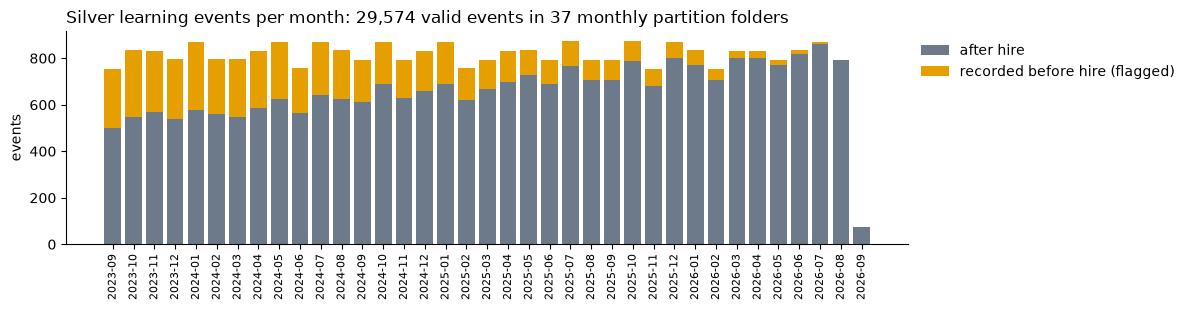

,Silver dataset,valid rows,flagged before hire,share
0,performance_reviews,4000,666,17%
1,competency_assessments,4000,234,6%
2,learning_events,29574,5161,17%


In [9]:
when = pd.to_datetime(events["event_ts"]).dt.to_period("M").astype(str)
monthly = (events.assign(month=when, before=events["recorded_before_hire"].fillna(False).astype(bool))
           .groupby(["month", "before"]).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0))
folders = {k.rsplit("/", 1)[0] for k in groups["silver/learning_events"]}

fig, ax = plt.subplots(figsize=(12, 3.2))
ax.bar(monthly.index, monthly[False], color=LAYER_COLOURS["silver"], label="after hire")
ax.bar(monthly.index, monthly[True], bottom=monthly[False], color="#E69F00", label="recorded before hire (flagged)")
ax.set_title(f"Silver learning events per month: {len(events):,} valid events in {len(folders)} monthly "
             "partition folders", loc="left")
ax.set_ylabel("events")
ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(1, 1))
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

flags = pd.DataFrame([{"Silver dataset": t, "valid rows": silver_m[f"{t}_valid"],
                       "flagged before hire": silver_m[f"{t}_before_hire"],
                       "share": f"{silver_m[f'{t}_before_hire'] / silver_m[f'{t}_valid']:.0%}"}
                      for t in [k[:-len("_before_hire")] for k in silver_m if k.endswith("_before_hire")]])
flags

## 5. Quarantine — rejected rows, nothing silently dropped

Every rejected row keeps **why** (`reject_reason`), **what** (`raw_record`, exactly as received) and **where**
(`_source_file` + `_source_line`). Quarantine datasets only exist for entities that had rejects.

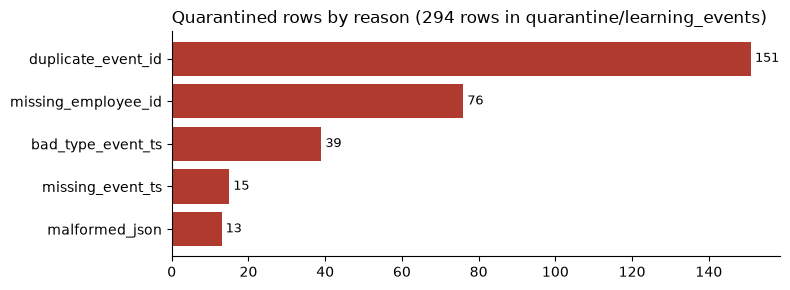

One example of each reason:

,entity,reject_reason,_source_file,_source_line,raw_record
0,learning_events,malformed_json,bronze/learning_activity/year=2023/month=11/day=22/events-000.jsonl,3,"{""event_id"": ""EV0000002169"", ""employee_id"": ""1020"", ""event_date"": ""2023-11-22T08:32:00"", ""event_type"": ""module_started"
13,learning_events,bad_type_event_ts,bronze/learning_activity/year=2023/month=09/day=05/events-000.jsonl,1,"{""event_id"": ""EV0000000039"", ""employee_id"": ""325"", ""event_date"": ""yesterday"", ""event_type"": ""enrollment"", ""course_na..."
14,learning_events,missing_employee_id,bronze/learning_activity/year=2023/month=09/day=13/events-000.jsonl,23,"{""event_id"": ""EV0000000289"", ""employee_id"": null, ""event_date"": ""2023-09-13T16:03:00"", ""event_type"": ""module_started..."
15,learning_events,duplicate_event_id,bronze/learning_activity/year=2023/month=09/day=13/events-000.jsonl,26,"{""event_id"": ""EV0000000291"", ""employee_id"": ""1923"", ""event_date"": ""2023-09-13T16:27:00"", ""event_type"": ""module_compl..."
20,learning_events,missing_event_ts,bronze/learning_activity/year=2023/month=09/day=21/events-000.jsonl,22,"{""event_id"": ""EV0000000515"", ""employee_id"": ""1870"", ""event_date"": """", ""event_type"": ""module_completed"", ""course_name..."


In [10]:
quarantine_names = [d for d in inventory["dataset"] if d.startswith("quarantine/")]
quarantine = pd.concat([load(n).to_pandas() for n in quarantine_names], ignore_index=True) if quarantine_names \
    else pd.DataFrame(columns=["reject_reason", "raw_record"])
reasons = quarantine["reject_reason"].str.split(";").explode().value_counts()

if reasons.empty:
    print("Nothing was quarantined in this run.")
else:
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(reasons) + 1))
    ax.barh(reasons.index[::-1], reasons.values[::-1], color=LAYER_COLOURS["quarantine"])
    for y, n in enumerate(reasons.values[::-1]):
        ax.text(n, y, f" {n}", va="center", fontsize=9)
    ax.set_title(f"Quarantined rows by reason ({len(quarantine):,} rows in {', '.join(quarantine_names)})",
                 loc="left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.show()
    shown_cols = [c for c in ("entity", "reject_reason", "_source_file", "_source_line", "raw_record")
                  if c in quarantine.columns]
    display(Markdown("One example of each reason:"))
    display(quarantine.drop_duplicates("reject_reason")[shown_cols])

In [11]:
TRACE_REASON = "malformed_json"   # pick a reason from the chart above

matches = quarantine[quarantine["reject_reason"].str.contains(TRACE_REASON, regex=False)]
if matches.empty or "_source_file" not in matches.columns:
    print(f"No quarantined row with reason {TRACE_REASON!r} and a source file to trace.")
else:
    reject = matches.iloc[0]
    line = read_text(reject["_source_file"]).splitlines()[reject["_source_line"] - 1]
    print(f"Quarantine says: {reject['reject_reason']} at {reject['_source_file']}, line {reject['_source_line']}")
    print(f"\nThat line in Bronze:\n  {line}\n")
    print("Same as raw_record in quarantine ✓" if line == reject["raw_record"] else "Different from raw_record ✗")

Quarantine says: malformed_json at bronze/learning_activity/year=2023/month=11/day=22/events-000.jsonl, line 3

That line in Bronze:
  {"event_id": "EV0000002169", "employee_id": "1020", "event_date": "2023-11-22T08:32:00", "event_type": "module_started

Same as raw_record in quarantine ✓


## 6. Gold — one table per business question

Gold tables are built only from Silver (and from each other), checked before they are published (unique grain,
no employee dropped, totals that reconcile with Silver), and replaced as a whole on each run.
`insights.ipynb` turns them into charts and findings.

In [12]:
GOLD_QUESTIONS = {
    "employee_performance_history": "Q1 ratings and review history for each employee",
    "employee_skill_gaps": "Q2 critical skill gaps (one row per assessment)",
    "promotion_readiness": "Q3 high-potential employees ready for promotion",
    "employee_learning_summary": "Q4 training completed per employee",
    "attrition_risk": "Q5 attrition risk from performance trends",
    "team_performance_outcomes": "Q6 performance vs team and project outcomes",
    "skill_distribution": "Q7 distribution of skills",
}
gold_inventory = inventory[inventory["layer"] == "gold"].set_index("dataset")
pd.DataFrame([{
    "Gold table": name, "answers": GOLD_QUESTIONS.get(name.split("/", 1)[1], ""),
    "rows": gold_inventory.loc[name, "rows"], "columns": len(load(name).schema),
    "built from": ", ".join(lineage.get(name, [])),
} for name in gold_inventory.index])

,Gold table,answers,rows,columns,built from
0,gold/attrition_risk,Q5 attrition risk from performance trends,2000,21,"silver/dim_employee, silver/talent_review, gold/employee_performance_history, gold/employee_learning_summary"
1,gold/employee_learning_summary,Q4 training completed per employee,2000,25,"silver/learning_events, silver/dim_employee"
2,gold/employee_performance_history,Q1 ratings and review history for each employee,4000,20,"silver/performance_reviews, silver/dim_employee"
3,gold/employee_skill_gaps,Q2 critical skill gaps (one row per assessment),4000,20,"silver/competency_assessments, silver/competencies, silver/dim_employee"
4,gold/promotion_readiness,Q3 high-potential employees ready for promotion,2000,21,"silver/dim_employee, silver/talent_review, gold/employee_performance_history, gold/employee_skill_gaps"
5,gold/skill_distribution,Q7 distribution of skills,400,16,gold/employee_skill_gaps
6,gold/team_performance_outcomes,Q6 performance vs team and project outcomes,100,18,"silver/teams, silver/dim_employee, gold/employee_performance_history, silver/projects"


In [13]:
GOLD_PREVIEW = "promotion_readiness"   # any Gold table from the list above

load(f"gold/{GOLD_PREVIEW}").to_pandas().head(5)

,employee_id,full_name,job_level,hire_date,tenure_years,team_id,team_name,department,review_cycle,potential_rating,promotion_readiness,attrition_risk,latest_review_period,latest_rating,latest_review_before_hire,critical_gap_count,is_high_potential,is_promotion_ready,promotion_tier,_run_id,_as_of_date
0,1,Heather Davis,Director,2024-04-06,2.5,1,Team LightYellow-1,Sales,2025-H1,High,Ready Now,High,2025-H1,4,False,0,True,True,ready_strong,20261015T171915Z-6bf88104,2026-10-15
1,2,Kristie Heath,Director,2021-05-23,5.4,1,Team LightYellow-1,Sales,2025-H1,High,1-2 Years,Low,2025-H1,5,False,1,True,False,pipeline,20261015T171915Z-6bf88104,2026-10-15
2,3,Brandon Scott,Senior Manager,2020-03-30,6.5,1,Team LightYellow-1,Sales,2025-H1,Low,Not Ready,Low,2025-H1,5,False,0,False,False,not_ready,20261015T171915Z-6bf88104,2026-10-15
3,4,Gregory Williams,IC3,2020-01-06,6.8,1,Team LightYellow-1,Sales,2025-H1,Low,Not Ready,Low,2025-H1,4,False,0,False,False,not_ready,20261015T171915Z-6bf88104,2026-10-15
4,5,Linda Murray,IC1,2025-11-01,1.0,1,Team LightYellow-1,Sales,2025-H1,Medium,1-2 Years,Low,2025-H1,3,True,1,False,False,not_ready,20261015T171915Z-6bf88104,2026-10-15


## 7. Browse any dataset

The notebook version of `scripts/inspect_lake.py`. Set the dataset (any name from the inventory at the top, or a
file such as `_runs/latest.json`), optionally filter, and re-run **just this cell**.

In [14]:
# ============================ EDIT HERE ============================
DATASET = "silver/employees"   # e.g. "gold/attrition_risk", "bronze/postgres/teams", "_runs/latest.json"
FILTERS = {}                   # only rows where column == value, e.g. {"employee_id": 1332}
COLUMNS = []                   # only these columns, e.g. ["employee_id", "full_name"]   ([] = all)
ROWS = 10                      # how many rows to show
# ================== nothing to change below this line ==================

# This cell only needs the FIRST cell under "Setup", so after that has run once you can change the
# settings above and re-run just this cell.
if "inventory" not in globals():
    raise RuntimeError("The lake isn't loaded yet. Scroll to the top, run the first code cell under 'Setup' "
                       "(or use Run All once), then run this cell again.")

name = DATASET.strip().strip("/")
keys = {k: size for k, size in FILES.items() if k == name or k.startswith(name + "/")}
if not keys:
    print(f"Nothing at s3://{BUCKET}/{name}. Datasets in this lake:\n  " + "\n  ".join(inventory["dataset"]))
elif all(k.endswith(".json") for k in keys):            # run manifests / latest.json
    key = sorted(keys)[-1]
    print(f"{key}:\n{json.dumps(read_json(key), indent=2)[:6000]}")
elif all(k.endswith(".jsonl") for k in keys):           # raw Bronze event files
    key = next((k for k in sorted(keys) if keys[k] > 0), sorted(keys)[0])
    print(f"{len(keys):,} raw JSON Lines file(s). First {ROWS} line(s) of {key}:\n")
    print("\n".join("  " + line for line in read_text(key).splitlines()[:ROWS]))
else:
    table = load(name)
    folders = sorted({k[len(name) + 1:].rsplit("/", 1)[0] for k in keys if "=" in k})
    display(Markdown(f"`s3://{BUCKET}/{name}/` — **{table.num_rows:,} rows**, {len(keys)} file(s), "
                     f"{sum(keys.values()) / 1024:,.0f} KB"
                     + (f", {len(folders)} partition folder(s): {', '.join(folders[:4])}"
                        f"{' …' if len(folders) > 4 else ''}" if folders else "")))
    display(schema_table(table))
    df = table.to_pandas()
    for column, value in FILTERS.items():                # compared as text, so 1332 and "1332" both work
        if column not in df.columns:
            raise KeyError(f"FILTERS: no column {column!r} in {name}. Columns: {', '.join(df.columns)}")
        df = df[df[column].astype(str) == str(value)]
    if COLUMNS:
        missing = [c for c in COLUMNS if c not in df.columns]
        if missing:
            raise KeyError(f"COLUMNS: unknown {missing}. Columns: {', '.join(df.columns)}")
        df = df[COLUMNS]
    if FILTERS:
        print(f"{len(df):,} row(s) match {FILTERS}" + (f" (showing {ROWS})" if len(df) > ROWS else ""))
    display(df.head(ROWS))

`s3://coding-workshop-datalake-77a23259/silver/employees/` — **2,000 rows**, 1 file(s), 72 KB

,column,type,note
0,employee_id,int64,
1,first_name,large_string,
2,last_name,large_string,
3,email,large_string,
4,team_id,int64,
5,job_level,large_string,
6,hire_date,date32[day],
7,_bronze_run_id,large_string,lineage: the run that wrote the Bronze snapshot it was cleaned from
8,_ingested_at,"timestamp[us, tz=UTC]",lineage: when Bronze copied it (UTC)
9,_source,large_string,lineage: where it was copied from


,employee_id,first_name,last_name,email,team_id,job_level,hire_date,_bronze_run_id,_ingested_at,_source,_run_id
0,1,Heather,Davis,heather.davis.1@acme-corp.example,1,Director,2024-04-06,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
1,2,Kristie,Heath,kristie.heath.2@acme-corp.example,1,Director,2021-05-23,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
2,3,Brandon,Scott,brandon.scott.3@acme-corp.example,1,Senior Manager,2020-03-30,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
3,4,Gregory,Williams,gregory.williams.4@acme-corp.example,1,IC3,2020-01-06,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
4,5,Linda,Murray,linda.murray.5@acme-corp.example,1,IC1,2025-11-01,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
5,6,Claudia,Cole,claudia.cole.6@acme-corp.example,1,Manager,2019-09-04,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
6,7,April,Harrington,april.harrington.7@acme-corp.example,1,IC3,2025-08-24,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
7,8,Sherry,Coleman,sherry.coleman.8@acme-corp.example,1,IC2,2023-05-22,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
8,9,Kyle,Brown,kyle.brown.9@acme-corp.example,1,Senior Manager,2018-10-30,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104
9,10,Tracie,Gomez,tracie.gomez.10@acme-corp.example,1,IC1,2023-11-18,20261015T171915Z-6bf88104,2026-10-15 17:19:15.308291+00:00,postgres://localhost/postgres/hr.employees,20261015T171915Z-6bf88104


## 8. Follow one employee through every layer

Where one person's records are in each layer — and their review history traced Bronze → Silver → Gold.

In [15]:
# ============================ EDIT HERE ============================
EMPLOYEE_ID = 1332   # any employee number
# ================== nothing to change below this line ==================

if "inventory" not in globals():
    raise RuntimeError("The lake isn't loaded yet. Scroll to the top, run the first code cell under 'Setup' "
                       "(or use Run All once), then run this cell again.")

people = load("silver/dim_employee").to_pandas()
person = people[people["employee_id"] == EMPLOYEE_ID]
if person.empty:
    print(f"No employee with ID {EMPLOYEE_ID}. IDs run from {people['employee_id'].min()} "
          f"to {people['employee_id'].max()}.")
else:
    p = person.iloc[0]
    display(Markdown(f"### {p['full_name']} — {p['job_level']}, {p['team_name']} ({p['department']}), "
                     f"hired {p['hire_date']}"))
    presence = []
    for name in inventory["dataset"]:
        if layer_of(name) not in ("bronze", "silver", "gold") or name == "bronze/learning_activity":
            continue
        table = load(name)
        if "employee_id" in table.schema.names:
            ids = table.column("employee_id").to_pandas()
            presence.append({"layer": layer_of(name), "dataset": name, "rows for this employee":
                             int((ids.astype(str) == str(EMPLOYEE_ID)).sum())})
    if "quarantine" in globals() and len(quarantine):   # rejected rows: search the original text
        pattern = rf'"employee_id":\s*"?{EMPLOYEE_ID}"?[,}}]'
        presence.append({"layer": "quarantine", "dataset": "quarantine (searched in raw_record)",
                         "rows for this employee": int(quarantine["raw_record"].str.contains(pattern).sum())})
    display(pd.DataFrame(presence))

    review_cols = ["review_id", "review_period", "rating", "submitted_date"]
    for name, cols in [("bronze/postgres/performance_reviews", review_cols + ["_source", "ingest_date"]),
                       ("silver/performance_reviews", review_cols + ["recorded_before_hire", "_bronze_run_id"]),
                       ("gold/employee_performance_history",
                        ["review_period", "rating", "previous_rating", "rating_change", "recorded_before_hire"])]:
        df = load(name).to_pandas()
        display(Markdown(f"**{name}**"))
        display(df[df["employee_id"] == EMPLOYEE_ID][[c for c in cols if c in df.columns]])

    mine = events[events["employee_id"] == EMPLOYEE_ID]
    display(Markdown(f"**silver/learning_events** — {len(mine)} events from "
                     f"{mine['_source_file'].nunique()} raw file(s); the first three, with where each came from:"))
    display(mine.sort_values("event_ts")[["event_ts", "event_type", "course_name", "score",
                                          "_source_file", "_source_line"]].head(3))

### Christopher Little — IC1, Team Fuchsia-68 (Human Resources), hired 2026-08-02

,layer,dataset,rows for this employee
0,bronze,bronze/postgres/competency_assessments,2
1,bronze,bronze/postgres/employees,1
2,bronze,bronze/postgres/performance_reviews,2
3,bronze,bronze/postgres/talent_review,1
4,silver,silver/competency_assessments,2
5,silver,silver/dim_employee,1
6,silver,silver/employees,1
7,silver,silver/learning_events,14
8,silver,silver/performance_reviews,2
9,silver,silver/talent_review,1


**bronze/postgres/performance_reviews**

,review_id,review_period,rating,submitted_date,_source,ingest_date
2662,2663,2024-H2,2,2025-08-25,postgres://localhost/postgres/hr.performance_reviews,2026-10-15
2663,2664,2025-H1,3,2026-02-17,postgres://localhost/postgres/hr.performance_reviews,2026-10-15


**silver/performance_reviews**

,review_id,review_period,rating,submitted_date,recorded_before_hire,_bronze_run_id
2662,2663,2024-H2,2,2025-08-25,True,20261015T171915Z-6bf88104
2663,2664,2025-H1,3,2026-02-17,True,20261015T171915Z-6bf88104


**gold/employee_performance_history**

,review_period,rating,previous_rating,rating_change,recorded_before_hire
2662,2024-H2,2,<NA>,<NA>,True
2663,2025-H1,3,2,1,True


**silver/learning_events** — 14 events from 14 raw file(s); the first three, with where each came from:

,event_ts,event_type,course_name,score,_source_file,_source_line
2800,2023-09-14 10:19:00,quiz_attempted,New Hire Onboarding Enablement,76,bronze/learning_activity/year=2023/month=09/day=14/events-000.jsonl,36
1423,2023-11-22 12:27:00,enrollment,Technical Writing Workshop,<NA>,bronze/learning_activity/year=2023/month=11/day=22/events-000.jsonl,21
2253,2023-12-22 07:21:00,quiz_passed,Resolving Team Conflict,71,bronze/learning_activity/year=2023/month=12/day=22/events-000.jsonl,19


## 9. Pipeline runs — what ran, when, and with which code

Every run writes a **manifest** to `_runs/run_date=<day>/<run_id>.json`: status, each step's row counts, time and
memory, the configuration, the package versions and a SHA-256 fingerprint of `job.py`. `_runs/latest.json` points
to the last *complete, successful* run — the one readers should trust.

**1 run(s) recorded** (most recent last)

,run_id,status,steps,started (UTC),duration_s,exit_code,code sha256,latest
0,20261015T171915Z-6bf88104,succeeded,"preflight, bronze, silver, gold",2026-10-15 17:19:15,6.9,0,3d2aacec887a,◀ latest


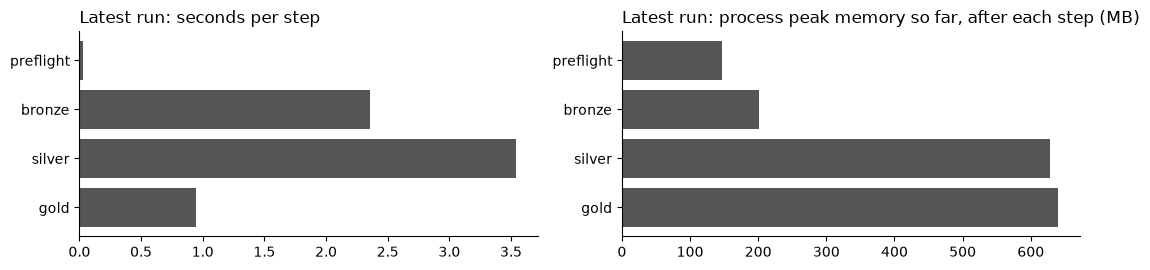

,value
config.is_local,True
config.source,postgres://localhost:5432/postgres/hr
config.landing_bucket,coding-workshop-landing-77a23259
config.lake_bucket,coding-workshop-datalake-77a23259
config.aws_region,ap-south-1
code.python,3.13.16
package.pandas,3.0.6
package.numpy,2.4.6
package.pyarrow,24.0.0
package.boto3,1.43.100


In [16]:
manifests = [read_json(k) for k in sorted(FILES) if k.startswith("_runs/run_date=") and k.endswith(".json")]
runs = pd.DataFrame([{
    "run_id": m["run_id"], "status": m["status"], "steps": ", ".join(s["name"] for s in m["steps"]),
    "started (UTC)": m["started_at"][:19].replace("T", " "),
    "duration_s": (round((pd.Timestamp(m["finished_at"]) - pd.Timestamp(m["started_at"])).total_seconds(), 1)
                   if m.get("finished_at") else None),
    "exit_code": m.get("exit_code"), "code sha256": m["code"]["sha256"][:12],
    "latest": "◀ latest" if m["run_id"] == latest["run_id"] else "",
} for m in manifests])
display(Markdown(f"**{len(runs)} run(s) recorded** (most recent last)"))
display(runs.tail(20))

steps = pd.DataFrame(manifest["steps"]).set_index("name")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 2.8))
left.barh(steps.index[::-1], steps["duration_s"][::-1], color="#555555")
left.set_title("Latest run: seconds per step", loc="left")
right.barh(steps.index[::-1], steps["peak_rss_mb"][::-1], color="#555555")
right.set_title("Latest run: process peak memory so far, after each step (MB)", loc="left")
for ax in (left, right):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

pd.DataFrame({"value": {**{f"config.{k}": v for k, v in manifest["config"].items()},
                        "code.python": manifest["code"]["python"],
                        **{f"package.{k}": v for k, v in manifest["code"]["packages"].items()}}})

## Where to go next

* **The business answers:** `insights.ipynb` (same folder).
* **Column-level lineage and every reject reason:** `data/LINEAGE.md`.
* **The same views from a terminal:** `scripts/inspect_lake.py --list` (add `--cloud` for AWS).